# 12.1-HouseEnergyRegreesion

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("12-house_energy_regression.csv")

In [5]:
df.head()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
0,-0.167118,0.146714,-14.996950
1,-0.020902,0.117327,-12.678089
2,0.150419,0.364961,17.775455
3,0.555604,0.089581,6.661465
4,0.058209,-1.142970,-14.195530


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   avg_indoor_temp_change        1000 non-null   float64
 1   outdoor_humidity_level        1000 non-null   float64
 2   daily_energy_consumption_kwh  1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB


In [7]:
df.describe()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
count,1000.000000,1000.000000,1000.000000
mean,0.033186,0.056982,1.766025
std,0.961603,1.014959,41.299085
min,-3.241267,-2.940389,-132.797922
25%,-0.611581,-0.651418,-25.600072
50%,0.036043,0.047742,1.065474
75%,0.648317,0.714886,28.766573
max,3.078881,3.852731,138.577662


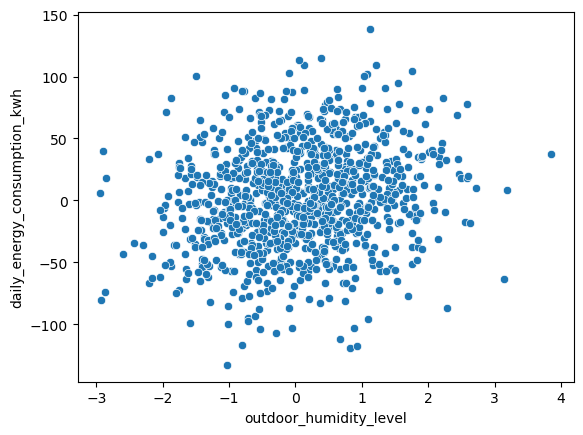

In [8]:
sns.scatterplot(x=df["outdoor_humidity_level"],
               y=df["daily_energy_consumption_kwh"])
plt.show()

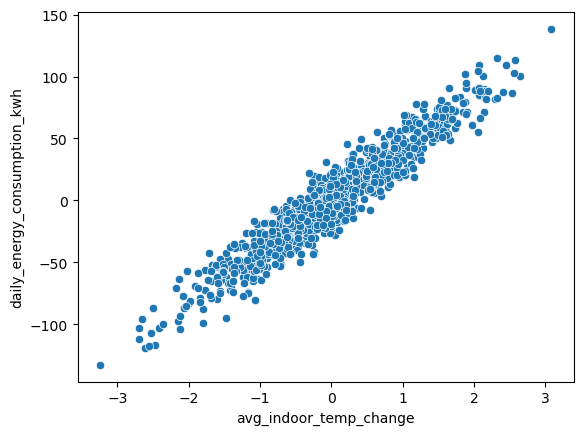

In [9]:
sns.scatterplot(x=df["avg_indoor_temp_change"],
               y=df["daily_energy_consumption_kwh"])
plt.show()

In [10]:
df.corr()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
avg_indoor_temp_change,1.000000,0.002584,0.956682
outdoor_humidity_level,0.002584,1.000000,0.169557
daily_energy_consumption_kwh,0.956682,0.169557,1.000000


In [13]:
X = df.drop("daily_energy_consumption_kwh",axis=1)
y=df["daily_energy_consumption_kwh"]

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=15)

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
from sklearn.neighbors import KNeighborsRegressor

In [21]:
regressor = KNeighborsRegressor(n_neighbors=5,
                                algorithm="auto")

In [23]:
regressor.fit(X_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [24]:
y_pred = regressor.predict(X_test_scaled)

In [25]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [26]:
print("r2 score:",r2_score(y_test,y_pred))
print("mean absolute error:",mean_absolute_error(y_test,y_pred))
print("mean squared error:",mean_squared_error(y_test,y_pred))

r2 score: 0.9152685146562609
mean absolute error: 9.42143518926242
mean squared error: 140.40201685069158


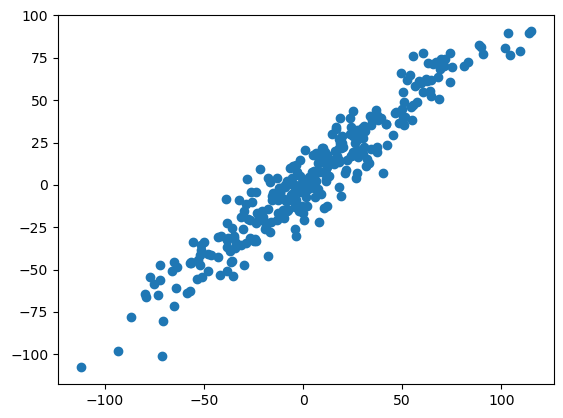

In [27]:
plt.scatter(y_test,y_pred)
plt.show()

In [28]:
regressor = KNeighborsRegressor(n_neighbors=7,
                                algorithm="auto")

In [29]:
regressor.fit(X_train_scaled,y_train)

,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [30]:
y_pred = regressor.predict(X_test_scaled)

In [31]:
print("r2 score:",r2_score(y_test,y_pred))
print("mean absolute error:",mean_absolute_error(y_test,y_pred))
print("mean squared error:",mean_squared_error(y_test,y_pred))

r2 score: 0.9164863388635838
mean absolute error: 9.331428506491209
mean squared error: 138.38405417502187


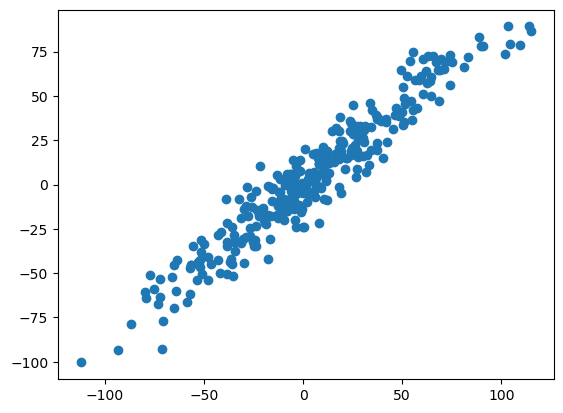

In [32]:
plt.scatter(y_test,y_pred)
plt.show()

r2 score: 0.9054596209710335
mean absolute error: 9.62138061650753
mean squared error: 156.65557892260577


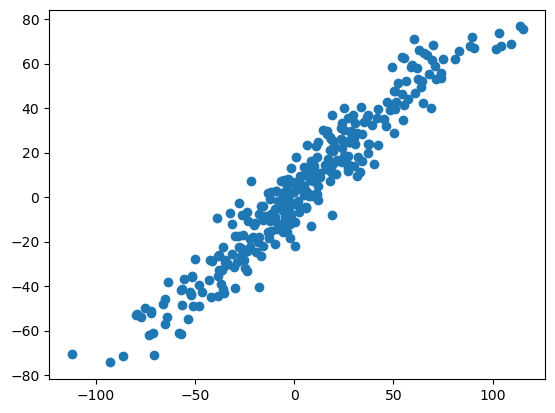

In [33]:
regressor = KNeighborsRegressor(n_neighbors=35,
                                algorithm="auto")
#n_neighbors=35 verdik abarttık abarrtıgımızda şaşıyor.
regressor.fit(X_train_scaled,y_train)
y_pred = regressor.predict(X_test_scaled)
print("r2 score:",r2_score(y_test,y_pred))
print("mean absolute error:",mean_absolute_error(y_test,y_pred))
print("mean squared error:",mean_squared_error(y_test,y_pred))
plt.scatter(y_test,y_pred)
plt.show()